# 03 · Smart Basket A/B Test

> **Read this first: the test is simulated.** Olist never launched Smart Basket, so no historical data can show what treatment customers *would* have done. This notebook replays a real 11-week window of Olist orders. **Control orders are exactly what happened.** Treatment customers get the same real order, plus a simulated widget (impression → click → add) whose behaviour is set by documented parameters ([`docs/04_Experiment_Design_and_Assumptions.md`](../docs/04_Experiment_Design_and_Assumptions.md)).
>
> Because the true effect is known, the notebook can also check that the analysis **recovers** it. That's the real skill on display: designing, validating and reading an experiment correctly.

## Pre-registered design

Fixed *before* looking at any treatment data:

| | |
|---|---|
| **Hypothesis** | Showing 3 "frequently bought together" category recommendations at checkout increases the share of orders with more than one product. |
| **Unit of randomisation** | Customer (`customer_unique_id`), hash-based 50/50. The same person always sees the same experience. |
| **Population** | Every customer who places an order from 5 Mar to 20 May 2018 (11 full weeks). |
| **Primary metric** | Multi-product order rate = orders with ≥2 distinct products ÷ orders |
| **Secondary metrics** | GMV per customer · AOV · items per order (Holm-corrected) |
| **Guardrails** (non-inferiority) | Cancellation rate must not rise by >0.3 pp · Review score must not fall by >0.05 · Late-delivery rate must not rise by >1 pp |
| **Test / α / power** | Two-sided, α = 0.05, power = 80%, delta-method variance (customer-clustered) |
| **MDE** | +0.8 pp absolute on a ~2.8% baseline (≈ +28% relative) |
| **Decision rule** | **Ship** if the primary 95% CI is entirely above 0 *and* every guardrail passes. **Iterate** if the primary is positive but not significant. **Stop** if the primary is negative or any guardrail fails. |

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from smart_basket import config, data_model as dm, experiment as ex, plotting as P, simulation as sim
from smart_basket.recommender import CategoryAffinityRecommender

P.use_style()
pd.set_option("display.float_format", "{:,.4f}".format)

t = dm.load_tables()
orders, order_items = t["orders"], t["order_items"]

START, END = pd.Timestamp("2018-03-05"), pd.Timestamp("2018-05-21")  # END exclusive -> 11 weeks
PRE_START = START - pd.Timedelta(weeks=8)
MDE = 0.008
ALPHA, POWER = 0.05, 0.80
GUARDRAIL_MARGINS = {"cancellation_rate": 0.003, "review_score": -0.05, "late_delivery_rate": 0.01}

## 1. Baseline and sample size

The baseline comes from the 8 weeks *before* the test.

In [2]:
pre = orders[(orders["purchased_at"] >= PRE_START) & (orders["purchased_at"] < START)]
baseline = pre["is_multi_product"].mean()
n_required = ex.sample_size_two_proportions(baseline, MDE, ALPHA, POWER)
weekly_customers = pre.groupby(pre["purchased_at"].dt.to_period("W"))["customer_unique_id"].nunique().mean()
weeks_needed = int(np.ceil(2 * n_required / weekly_customers))

pd.Series(
    {
        "baseline multi-product rate (pre-period)": f"{baseline:.2%}",
        "MDE (absolute / relative)": f"+{MDE:.1%} / +{MDE / baseline:.0%}",
        "customers needed per arm": f"{n_required:,}",
        "customers per week (pre-period)": f"{weekly_customers:,.0f}",
        "weeks needed": weeks_needed,
        "weeks planned": (END - START).days // 7,
    }
).to_frame("design")

,design
baseline multi-product rate (pre-period),2.83%
MDE (absolute / relative),+0.8% / +28%
customers needed per arm,"7,668"
customers per week (pre-period),"1,662"
weeks needed,10
weeks planned,11


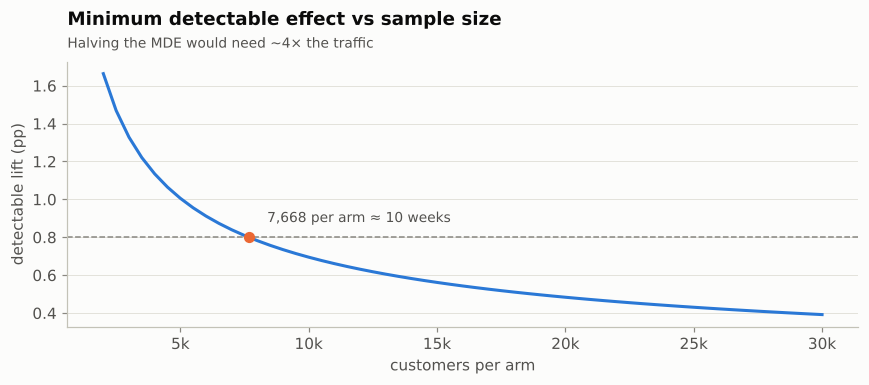

In [3]:
sizes = np.arange(2000, 30001, 500)
mdes = [ex.mde_for_sample_size(baseline, n, ALPHA, POWER) for n in sizes]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(sizes, np.array(mdes) * 100, color=P.SERIES[0])
ax.axhline(MDE * 100, color=P.MUTED, lw=1, ls="--")
ax.scatter([n_required], [MDE * 100], color=P.SERIES[1], s=40, zorder=3)
ax.annotate(f"{n_required:,} per arm ≈ {weeks_needed} weeks", (n_required, MDE * 100), xytext=(12, 10),
            textcoords="offset points", fontsize=9, color=P.INK_2)
ax.set_xlabel("customers per arm")
ax.set_ylabel("detectable lift (pp)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x / 1000:.0f}k"))
P.titled(ax, "Minimum detectable effect vs sample size", "Halving the MDE would need ~4× the traffic")
fig.tight_layout()
P.save(fig, "04_power_curve")
plt.show()

**Why +0.8 pp?** It's the smallest effect that's both *worth shipping* (~R$52k GMV a year; notebook 02) and *detectable in a reasonable time*. Detecting +0.5 pp would take more than 6 months of traffic, longer than any product team would wait.

## 2. A/A test: does the pipeline produce false positives?

Before trusting any result, we run 500 A/A tests on the pre-period: random splits with **no** treatment. A valid pipeline should flag about 5% of them as "significant" (α = 0.05), and the p-values should be uniformly distributed.

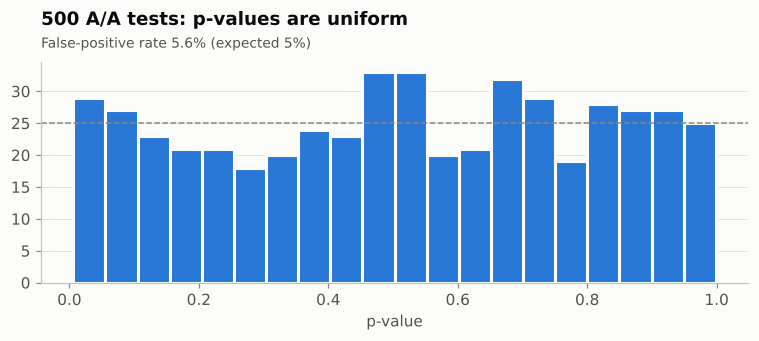

In [4]:
pre_cust = (
    pre.groupby("customer_unique_id")
    .agg(multi=("is_multi_product", "sum"), orders=("order_id", "size"))
    .reset_index()
)
aa_p = []
for i in range(500):
    pre_cust["variant"] = ex.assign_variant(pre_cust["customer_unique_id"], salt=f"aa-{i}")
    aa_p.append(ex.delta_method_ratio_test(pre_cust, "multi", "orders").p_value)
aa_p = np.array(aa_p)
false_positive_rate = (aa_p < ALPHA).mean()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(aa_p, bins=20, color=P.SERIES[0], edgecolor=P.SURFACE, linewidth=2)
ax.axhline(len(aa_p) / 20, color=P.MUTED, lw=1, ls="--")
ax.set_xlabel("p-value")
P.titled(ax, "500 A/A tests: p-values are uniform", f"False-positive rate {false_positive_rate:.1%} (expected 5%)")
fig.tight_layout()
plt.show()

## 3. Assignment and sanity checks

Treatment-only data was simulated *after* these checks passed.

In [5]:
exp = orders[(orders["purchased_at"] >= START) & (orders["purchased_at"] < END)].copy()
exp["variant"] = ex.assign_variant(exp["customer_unique_id"])

counts = exp.drop_duplicates("customer_unique_id")["variant"].value_counts()
srm_p = ex.srm_test(counts["control"], counts["treatment"])
assert srm_p > 0.001, "Sample ratio mismatch: stop and investigate"
print(f"Customers: control {counts['control']:,} · treatment {counts['treatment']:,} · SRM p = {srm_p:.3f} (pass)")
assert exp.groupby("customer_unique_id")["variant"].nunique().max() == 1
print("Every customer saw exactly one variant on every order (pass)")

Customers: control 9,063 · treatment 9,170 · SRM p = 0.428 (pass)
Every customer saw exactly one variant on every order (pass)


In [6]:
from scipy import stats

balance = exp.groupby("variant").agg(
    orders=("order_id", "size"),
    base_basket_value=("gmv", "mean"),
    returning_customers=("is_repeat_order", "mean"),
    home_category_share=("primary_category", lambda s: s.isin(["bed_bath_table", "furniture_decor", "housewares"]).mean()),
    sao_paulo_share=("customer_state", lambda s: (s == "SP").mean()),
).T
balance["difference"] = balance["treatment"] / balance["control"] - 1
c_, t_ = exp[exp["variant"] == "control"], exp[exp["variant"] == "treatment"]
balance["p-value"] = [
    np.nan,
    stats.ttest_ind(t_["gmv"], c_["gmv"], equal_var=False).pvalue,
    stats.ttest_ind(t_["is_repeat_order"], c_["is_repeat_order"]).pvalue,
    stats.ttest_ind(t_["primary_category"].isin(["bed_bath_table", "furniture_decor", "housewares"]),
                    c_["primary_category"].isin(["bed_bath_table", "furniture_decor", "housewares"])).pvalue,
    stats.ttest_ind(t_["customer_state"] == "SP", c_["customer_state"] == "SP").pvalue,
]
balance.style.format("{:,.3f}").format("{:+.1%}", subset=["difference"]).format("{:.2f}", subset=["p-value"], na_rep="").set_caption(
    "Pre-treatment balance (real data, before any simulated behaviour)"
)

variant,control,treatment,difference,p-value
orders,"9,176.000","9,296.000",+1.3%,
base_basket_value,162.689,167.282,+2.8%,0.15
returning_customers,0.033,0.033,-0.3%,0.97
home_category_share,0.211,0.208,-1.7%,0.55
sao_paulo_share,0.435,0.442,+1.4%,0.40


No pre-treatment difference is statistically significant, so randomisation worked. **But note the basket value:** treatment orders were already **2.8% larger before any simulated behaviour**, purely by chance (p = 0.15). Order values are heavily skewed, so random gaps of a few percent are normal. Keep this in mind when reading the revenue metrics in section 6.

## 4. Run the experiment (simulated treatment behaviour)

The recommender is trained **only on data before the test start**, so no future information leaks into the recommendations.

In [7]:
lines = order_items.merge(orders[["order_id", "customer_unique_id", "purchased_at", "is_canceled"]], on="order_id")
train = lines[(lines["purchased_at"] < START) & ~lines["is_canceled"]]
model = CategoryAffinityRecommender(k=3).fit(train)

params = sim.SimulationParams()
interests = sim.customer_interests(exp, orders, order_items)
result = sim.simulate(exp, interests, train, model, params)
pd.Series(params.to_dict()).to_frame("simulation parameter")

,simulation parameter
widget_load_rate,0.9800
p_click_relevant,0.2000
p_click_other,0.0500
p_add_given_click,0.2500
seed,42.0000


In [8]:
funnel = pd.Series(
    {
        "treatment orders": (result["variant"] == "treatment").sum(),
        "widget impressions": result["impression"].sum(),
        "clicks": result["clicked"].sum(),
        "recommended item added": result["added_recommendation"].sum(),
    }
)
funnel_tbl = funnel.to_frame("count")
funnel_tbl["conversion from previous step"] = (funnel / funnel.shift(1)).map(lambda x: "" if pd.isna(x) else f"{x:.1%}")
print(f"Control impressions: {result.loc[result['variant'] == 'control', 'impression'].sum()} · control clicks: "
      f"{result.loc[result['variant'] == 'control', 'clicked'].sum()} (must be 0: control never sees the widget)")
funnel_tbl

Control impressions: 0 · control clicks: 0 (must be 0: control never sees the widget)


,count,conversion from previous step
treatment orders,9296,
widget impressions,9113,98.0%
clicks,480,5.3%
recommended item added,112,23.3%


## 5. Primary metric: multi-product order rate

Randomisation is by **customer** but the metric is measured per **order**, so orders from the same customer are not independent. The delta method gives the correct customer-clustered variance. A cluster bootstrap (resampling whole customers) cross-checks it.

*This is the mistake the original version of this project made: it ran a t-test on order-line rows, treating ~1,400 lines from 319 customers as independent observations.*

In [9]:
per_customer = (
    result.groupby(["customer_unique_id", "variant"])
    .agg(
        orders=("order_id", "size"),
        multi=("is_multi_product", "sum"),
        items=("items_count", "sum"),
        gmv=("gmv", "sum"),
        canceled=("is_canceled", "sum"),
    )
    .reset_index()
)
# order-level guardrail metrics need their own denominators
rv = result.dropna(subset=["review_score"]).groupby(["customer_unique_id", "variant"]).agg(
    review_sum=("review_score", "sum"), reviewed=("review_score", "size")).reset_index()
lt = result.dropna(subset=["is_late"]).assign(is_late=lambda d: d["is_late"].astype(float)).groupby(
    ["customer_unique_id", "variant"]).agg(late=("is_late", "sum"), delivered=("is_late", "size")).reset_index()

primary = ex.delta_method_ratio_test(per_customer, "multi", "orders", metric="Multi-product order rate")
boot_lo, boot_hi = ex.cluster_bootstrap_ratio(per_customer, "multi", "orders", n_boot=2000, seed=1)

pd.DataFrame(
    {
        "control": [f"{primary.control:.2%}"],
        "treatment": [f"{primary.treatment:.2%}"],
        "absolute lift": [f"{primary.abs_diff * 100:+.2f} pp"],
        "relative lift": [f"{primary.rel_lift:+.1%}"],
        "95% CI (delta method)": [f"[{primary.ci_low * 100:+.2f}, {primary.ci_high * 100:+.2f}] pp"],
        "95% CI (cluster bootstrap)": [f"[{boot_lo * 100:+.2f}, {boot_hi * 100:+.2f}] pp"],
        "p-value": [f"{primary.p_value:.1e}"],
    },
    index=[primary.metric],
).T

,Multi-product order rate
control,3.25%
treatment,4.63%
absolute lift,+1.38 pp
relative lift,+42.4%
95% CI (delta method),"[+0.82, +1.94] pp"
95% CI (cluster bootstrap),"[+0.84, +1.94] pp"
p-value,1.5e-06


### Does the analysis recover the true effect?

Because the simulation parameters are known, we can compute the effect the analysis *should* find and check it's inside the confidence interval.

In [10]:
t_orders = result[result["variant"] == "treatment"]
single = ~t_orders["is_multi_product"] | t_orders["added_recommendation"]          # orders that started single-product
p_click = np.where(t_orders["recommendation_relevant"], params.p_click_relevant, params.p_click_other)
true_effect = (params.widget_load_rate * p_click * params.p_add_given_click * single).mean()
recovered = primary.ci_low <= true_effect <= primary.ci_high
print(f"True (expected) lift: {true_effect * 100:+.2f} pp · estimated: {primary.abs_diff * 100:+.2f} pp · "
      f"inside 95% CI: {recovered}")
assert recovered

True (expected) lift: +1.21 pp · estimated: +1.38 pp · inside 95% CI: True


## 6. Secondary metrics (Holm-corrected)

In [11]:
secondary = [
    ex.delta_method_ratio_test(per_customer, "gmv", "orders", metric="AOV (R$)"),
    ex.delta_method_ratio_test(per_customer.assign(one=1), "gmv", "one", metric="GMV per customer (R$)"),
    ex.delta_method_ratio_test(per_customer, "items", "orders", metric="Items per order"),
]
sec = pd.DataFrame([r.as_dict() for r in secondary]).set_index("metric")
sec["p_holm"] = ex.holm_adjust(sec["p_value"].tolist())
sec["significant"] = np.where(sec["p_holm"] < ALPHA, "yes", "no")
sec[["control", "treatment", "rel_lift", "ci_low", "ci_high", "p_value", "p_holm", "significant"]].style.format(
    {"control": "{:,.3f}", "treatment": "{:,.3f}", "rel_lift": "{:+.1%}", "ci_low": "{:+.3f}", "ci_high": "{:+.3f}",
     "p_value": "{:.3f}", "p_holm": "{:.3f}"}
)

,control,treatment,rel_lift,ci_low,ci_high,p_value,p_holm,significant
metric,,,,,,,,
AOV (R$),162.689,168.537,+3.6%,-0.411,+12.107,0.067,0.118,no
GMV per customer (R$),164.717,170.853,+3.7%,-0.229,+12.501,0.059,0.118,no
Items per order,1.147,1.167,+1.7%,+0.003,+0.037,0.019,0.056,no


None of the secondary metrics is significant after Holm correction. Items per order is nominally significant (p ≈ 0.02) but not after correcting for three tests.

**Don't read the +3.6% AOV as a feature effect.** Section 3 showed treatment baskets were already 2.8% larger *before* the feature did anything. How much revenue did the feature itself add?

In [12]:
t_res = result[result["variant"] == "treatment"]
added_rev_per_order = (t_res["added_item_revenue"] + t_res["added_freight"]).sum() / len(t_res)
base_gap = (t_res["gmv"] - t_res["added_item_revenue"] - t_res["added_freight"]).mean() - result.loc[result["variant"] == "control", "gmv"].mean()
pd.Series(
    {
        "observed AOV difference": f"R${sec.loc['AOV (R$)', 'abs_diff']:+.2f}",
        "…of which pre-existing chance gap (base basket)": f"R${base_gap:+.2f}",
        "…of which added by Smart Basket": f"R${added_rev_per_order:+.2f} per order ({added_rev_per_order / sec.loc['AOV (R$)', 'control']:+.1%})",
        "AOV CI half-width (detectable effect, roughly)": f"±R${(sec.loc['AOV (R$)', 'ci_high'] - sec.loc['AOV (R$)', 'ci_low']) / 2:.2f}",
    }
).to_frame("decomposition")

,decomposition
observed AOV difference,R$+5.85
…of which pre-existing chance gap (base basket),R$+4.59
…of which added by Smart Basket,R$+1.25 per order (+0.8%)
"AOV CI half-width (detectable effect, roughly)",±R$6.26


The feature's real revenue effect is about **+R$1 per order (<1%)**, about five times smaller than the noise in AOV (±R$6). No test of this size could detect it. This is the most common trap in cross-sell experiments: a conversion metric moves clearly, while revenue is too noisy to confirm. Claiming a "+3.6% revenue lift" here would be wrong.

## 7. Guardrails (non-inferiority)

A guardrail **passes** if the 95% CI excludes harm beyond its margin.

*Simulation note: the simulation models only the widget's effect on the basket. Cancellations, reviews and delivery are real outcomes, so here they measure sampling noise only. In a live test this is where harm from split shipments would show up.*

In [13]:
g_rows = [
    (ex.delta_method_ratio_test(per_customer, "canceled", "orders", metric="cancellation_rate"), "increase"),
    (ex.delta_method_ratio_test(rv, "review_sum", "reviewed", metric="review_score"), "decrease"),
    (ex.delta_method_ratio_test(lt, "late", "delivered", metric="late_delivery_rate"), "increase"),
]
guard = []
for r, harm in g_rows:
    margin = GUARDRAIL_MARGINS[r.metric]
    passed = r.ci_high < margin if harm == "increase" else r.ci_low > margin
    guard.append({"guardrail": r.metric, "control": r.control, "treatment": r.treatment, "difference": r.abs_diff,
                  "95% CI": f"[{r.ci_low:+.4f}, {r.ci_high:+.4f}]", "harm margin": f"{margin:+.3f}",
                  "status": "PASS" if passed else "FAIL"})
guard = pd.DataFrame(guard).set_index("guardrail")
guard

,control,treatment,difference,95% CI,harm margin,status
guardrail,,,,,,
cancellation_rate,0.0020,0.0027,0.0007,"[-0.0007, +0.0021]",+0.003,PASS
review_score,4.0438,4.0446,0.0008,"[-0.0393, +0.0410]",-0.050,PASS
late_delivery_rate,0.0997,0.0963,-0.0033,"[-0.0120, +0.0054]",+0.010,PASS


## 8. Lift over time: is it a novelty effect?

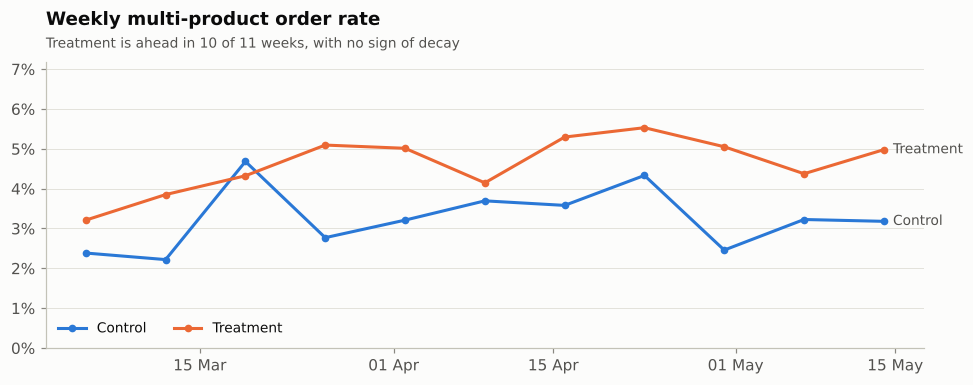

In [14]:
result["week"] = result["purchased_at"].dt.to_period("W").dt.start_time
weekly = result.pivot_table(index="week", columns="variant", values="is_multi_product", aggfunc="mean")
fig, ax = plt.subplots(figsize=(9, 3.6))
for v in ["control", "treatment"]:
    ax.plot(weekly.index, weekly[v], color=P.VARIANT_COLORS[v], marker="o", ms=4, label=v.capitalize())
    ax.annotate(v.capitalize(), (weekly.index[-1], weekly[v].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=P.INK_2)
weeks_ahead = int((weekly["treatment"] > weekly["control"]).sum())
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_ylim(0, weekly.max().max() * 1.3)
ax.legend(loc="lower left", ncol=2)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
P.titled(ax, "Weekly multi-product order rate", f"Treatment is ahead in {weeks_ahead} of {len(weekly)} weeks, with no sign of decay")
fig.tight_layout()
P.save(fig, "05_weekly_lift")
plt.show()

## 9. Primary result at a glance

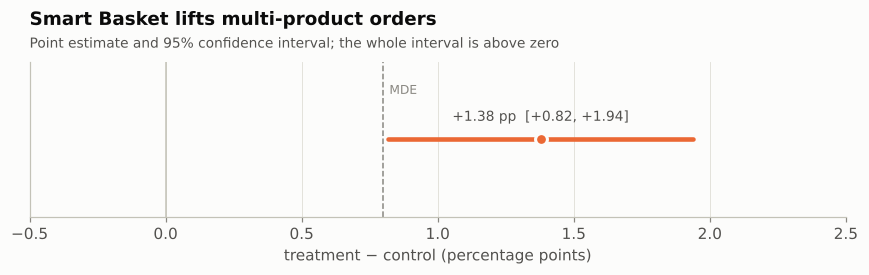

In [15]:
fig, ax = plt.subplots(figsize=(8, 2.6))
rows = [("Multi-product rate (pp)", primary.abs_diff * 100, primary.ci_low * 100, primary.ci_high * 100, MDE * 100)]
for i, (name, d, lo, hi, mde) in enumerate(rows):
    ax.plot([lo, hi], [i, i], color=P.SERIES[1], lw=3, solid_capstyle="round")
    ax.scatter([d], [i], color=P.SERIES[1], s=60, zorder=3, edgecolor=P.SURFACE, linewidth=2)
    ax.annotate(f"{d:+.2f} pp  [{lo:+.2f}, {hi:+.2f}]", (d, i), xytext=(0, 12), textcoords="offset points",
                ha="center", fontsize=9, color=P.INK_2)
ax.axvline(0, color=P.AXIS, lw=1)
ax.axvline(MDE * 100, color=P.MUTED, lw=1, ls="--")
ax.annotate("MDE", (MDE * 100, 0.35), xytext=(4, 0), textcoords="offset points", fontsize=8, color=P.MUTED)
ax.set_yticks([])
ax.set_ylim(-0.6, 0.6)
ax.set_xlim(-0.5, max(2.5, primary.ci_high * 100 + 0.3))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("treatment − control (percentage points)")
P.titled(ax, "Smart Basket lifts multi-product orders", "Point estimate and 95% confidence interval; the whole interval is above zero")
fig.tight_layout()
P.save(fig, "06_primary_result")
plt.show()

## 10. Segments (exploratory, Holm-corrected)

Segment results are for **generating hypotheses**, not for shipping decisions. With enough slices, something always looks significant by chance.

In [16]:
home = {"bed_bath_table", "furniture_decor", "housewares", "home_confort", "home_appliances", "kitchen_dining_laundry_garden_furniture"}
seg_defs = {
    "New customers": result["customer_order_number"] == 1,
    "Returning customers": result["customer_order_number"] > 1,
    "Home categories": result["primary_category"].isin(home),
    "Other categories": ~result["primary_category"].isin(home),
}
seg_rows = []
for name, mask in seg_defs.items():
    sub = result[mask].groupby(["customer_unique_id", "variant"]).agg(multi=("is_multi_product", "sum"), orders=("order_id", "size")).reset_index()
    r = ex.delta_method_ratio_test(sub, "multi", "orders", metric=name)
    seg_rows.append({**r.as_dict(), "customers": len(sub)})
seg = pd.DataFrame(seg_rows).set_index("metric")
seg["p_holm"] = ex.holm_adjust(seg["p_value"].tolist())
seg[["customers", "control", "treatment", "abs_diff", "ci_low", "ci_high", "p_holm"]].style.format(
    {"customers": "{:,.0f}", "control": "{:.2%}", "treatment": "{:.2%}", "abs_diff": "{:+.2%}", "ci_low": "{:+.2%}",
     "ci_high": "{:+.2%}", "p_holm": "{:.3f}"}
)

,customers,control,treatment,abs_diff,ci_low,ci_high,p_holm
metric,,,,,,,
New customers,"17,861",3.13%,4.51%,+1.37%,+0.81%,+1.93%,0.000
Returning customers,587,6.58%,8.14%,+1.56%,-2.67%,+5.80%,0.469
Home categories,"4,101",5.23%,7.39%,+2.16%,+0.68%,+3.64%,0.008
Other categories,"14,168",2.67%,3.83%,+1.16%,+0.58%,+1.74%,0.000


Returning customers are a small segment (~3% of customers), so their interval is very wide. "Target high-value repeat customers first", the original project's headline recommendation, **can't be supported** by this data. That would need a dedicated, longer test.

## 11. Decision

In [17]:
guardrails_ok = (guard["status"] == "PASS").all()
if primary.ci_low > 0 and guardrails_ok:
    decision = "SHIP"
elif primary.abs_diff > 0 and guardrails_ok:
    decision = "ITERATE"
else:
    decision = "STOP"
revenue_sig = sec.loc["GMV per customer (R$)", "significant"] == "yes"
print(f"Decision by pre-registered rule: {decision}")
print(f"Primary lift significant: {primary.ci_low > 0} · all guardrails pass: {guardrails_ok} · revenue lift significant: {revenue_sig}")

Decision by pre-registered rule: SHIP
Primary lift significant: True · all guardrails pass: True · revenue lift significant: False


**Recommendation: ship Smart Basket to 90% of customers and keep a 10% long-term holdout.**

* The primary metric moved clearly: +1.38 pp (+42%), with the whole 95% CI above zero, a point estimate above the pre-registered MDE, and a result that matches the known simulated effect (+1.21 pp).
* No guardrail was breached.
* The revenue effect is real but tiny (~+R$1 per order) and **undetectable at this sample size**. The visible +3.6% AOV gap is mostly chance. The holdout lets us measure revenue and repeat purchases over months of data instead of extending this test.
* The biggest lever for v2 is **value per add**, not more adds: price-aware ranking, product-level (not category-level) recommendations, and items from the **same seller** to avoid split shipments and extra freight.

## 12. Save results

In [18]:
results = {
    "design": {"start": str(START.date()), "end_exclusive": str(END.date()), "weeks": (END - START).days // 7,
               "baseline": baseline, "mde_abs": MDE, "alpha": ALPHA, "power": POWER,
               "n_required_per_arm": n_required, "weeks_needed": weeks_needed},
    "aa_false_positive_rate": float(false_positive_rate),
    "customers": {"control": int(counts["control"]), "treatment": int(counts["treatment"])}, "srm_p": srm_p,
    "funnel": {k: int(v) for k, v in funnel.items()},
    "ctr": float(result["clicked"].sum() / result["impression"].sum()),
    "add_rate_given_click": float(result["added_recommendation"].sum() / result["clicked"].sum()),
    "primary": {**primary.as_dict(), "boot_ci": [boot_lo, boot_hi], "true_effect": float(true_effect)},
    "secondary": sec.reset_index().to_dict(orient="records"),
    "guardrails": guard.reset_index().to_dict(orient="records"),
    "segments": seg.reset_index().to_dict(orient="records"),
    "weekly": {str(k.date()): {"control": float(r["control"]), "treatment": float(r["treatment"])} for k, r in weekly.iterrows()},
    "weeks_treatment_ahead": weeks_ahead,
    "added_revenue_per_treatment_order": float(added_rev_per_order),
    "pre_treatment_aov_gap": float(base_gap),
    "decision": decision,
    "simulation_params": params.to_dict(),
}
(config.REPORTS_DIR / "experiment_results.json").write_text(json.dumps(results, indent=2, default=float))
print("saved reports/experiment_results.json")

saved reports/experiment_results.json
